# Restaurant Visitor Prediction

**Problem statement:** Currently many restaurants, including mine, don't know the number of people they might receive in a day, hence leading to either surplus or shortage.

**Project objective:** My project will help predict the number of customers that will eat in a restaurant on a given day, so that there is less surplus or shortage.

**Who uses the prediction and what for:** I the restaurant owner and chef will use the predicted number of visitors per day to plan cooking quantities and weekly stock purchases, reducing food waste and shortages.

**Dataset:** Recruit Restaurant Visitor Forecasting (Kaggle) – real data from Recruit Holdings' reservation system (Hot Pepper Gourmet) and point-of-sale system (AirREGI), covering 829 restaurants in Japan from January 2016 to April 2017.

**Why I chose this dataset:** I chose the dataset because it has real data from real restaurants, and it also has records of customers, which helps when predicting.

**Target:** Visitors – number of people who ate at a restaurant on a given day.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

visits = pd.read_csv("data/air_visit_data.csv", parse_dates=["visit_date"])
stores = pd.read_csv("data/air_store_info.csv")
dates = pd.read_csv("data/date_info.csv", parse_dates=["calendar_date"])
reserves = pd.read_csv("data/air_reserve.csv", parse_dates=["visit_datetime", "reserve_datetime"])

for name, table in [("visits", visits), ("stores", stores), ("dates", dates), ("reserves", reserves)]:
    print(f"{name}: {table.shape[0]:,} rows, {table.shape[1]} columns")

display(visits.head())
display(stores.head())
display(dates.head())
display(reserves.head())


visits: 252,108 rows, 3 columns
stores: 829 rows, 5 columns
dates: 517 rows, 3 columns
reserves: 92,378 rows, 4 columns


,air_store_id,visit_date,visitors
0,air_ba937bf13d40fb24,2016-01-13,25
1,air_ba937bf13d40fb24,2016-01-14,32
2,air_ba937bf13d40fb24,2016-01-15,29
3,air_ba937bf13d40fb24,2016-01-16,22
4,air_ba937bf13d40fb24,2016-01-18,6


,air_store_id,air_genre_name,air_area_name,latitude,longitude
0,air_0f0cdeee6c9bf3d7,Italian/French,Hyōgo-ken Kōbe-shi Kumoidōri,34.695124,135.197853
1,air_7cc17a324ae5c7dc,Italian/French,Hyōgo-ken Kōbe-shi Kumoidōri,34.695124,135.197853
2,air_fee8dcf4d619598e,Italian/French,Hyōgo-ken Kōbe-shi Kumoidōri,34.695124,135.197853
3,air_a17f0778617c76e2,Italian/French,Hyōgo-ken Kōbe-shi Kumoidōri,34.695124,135.197853
4,air_83db5aff8f50478e,Italian/French,Tōkyō-to Minato-ku Shibakōen,35.658068,139.751599


,calendar_date,day_of_week,holiday_flg
0,2016-01-01,Friday,1
1,2016-01-02,Saturday,1
2,2016-01-03,Sunday,1
3,2016-01-04,Monday,0
4,2016-01-05,Tuesday,0


,air_store_id,visit_datetime,reserve_datetime,reserve_visitors
0,air_877f79706adbfb06,2016-01-01 19:00:00,2016-01-01 16:00:00,1
1,air_db4b38ebe7a7ceff,2016-01-01 19:00:00,2016-01-01 19:00:00,3
2,air_db4b38ebe7a7ceff,2016-01-01 19:00:00,2016-01-01 19:00:00,6
3,air_877f79706adbfb06,2016-01-01 20:00:00,2016-01-01 16:00:00,2
4,air_db80363d35f10926,2016-01-01 20:00:00,2016-01-01 01:00:00,5


## 1. The data

The dataset comes as four related tables, linked by restaurant ID (air_store_id) and date. I needed more than just the visit file cause the visit file only had visit date and visitors which is not enough.So i merged the four files to get all the necessary information that we needed for my prediction.

| Table | One row = | Key columns |
|---|---|---|
| visits| one restaurant on one day | visitors (**target**) |
| stores | one restaurant | genre, area, latitude, longitude |
| dates | one calendar day | day of week, holiday flag |
| reserves | one booking | number of people booked |


In [2]:
reserves["visit_date"] = reserves["visit_datetime"].dt.normalize()

daily_reserves = (
    reserves.groupby(["air_store_id", "visit_date"], as_index=False)["reserve_visitors"].sum()
)

print(daily_reserves.shape)
daily_reserves.head()


(29830, 3)


,air_store_id,visit_date,reserve_visitors
0,air_00a91d42b08b08d9,2016-10-31,2
1,air_00a91d42b08b08d9,2016-12-05,9
2,air_00a91d42b08b08d9,2016-12-14,18
3,air_00a91d42b08b08d9,2016-12-17,2
4,air_00a91d42b08b08d9,2016-12-20,4


In [3]:
df = visits.merge(stores, on="air_store_id", how="left")

df = df.merge(dates, left_on="visit_date", right_on="calendar_date", how="left")
df = df.drop(columns="calendar_date")

df = df.merge(daily_reserves, on=["air_store_id", "visit_date"], how="left")
df["reserve_visitors"] = df["reserve_visitors"].fillna(0)

print(df.shape)
display(df.head())
df.isna().sum()


(252108, 10)


,air_store_id,visit_date,visitors,air_genre_name,air_area_name,latitude,longitude,day_of_week,holiday_flg,reserve_visitors
0,air_ba937bf13d40fb24,2016-01-13,25,Dining bar,Tōkyō-to Minato-ku Shibakōen,35.658068,139.751599,Wednesday,0,0.0
1,air_ba937bf13d40fb24,2016-01-14,32,Dining bar,Tōkyō-to Minato-ku Shibakōen,35.658068,139.751599,Thursday,0,0.0
2,air_ba937bf13d40fb24,2016-01-15,29,Dining bar,Tōkyō-to Minato-ku Shibakōen,35.658068,139.751599,Friday,0,0.0
3,air_ba937bf13d40fb24,2016-01-16,22,Dining bar,Tōkyō-to Minato-ku Shibakōen,35.658068,139.751599,Saturday,0,0.0
4,air_ba937bf13d40fb24,2016-01-18,6,Dining bar,Tōkyō-to Minato-ku Shibakōen,35.658068,139.751599,Monday,0,0.0


air_store_id        0
visit_date          0
visitors            0
air_genre_name      0
air_area_name       0
latitude            0
longitude           0
day_of_week         0
holiday_flg         0
reserve_visitors    0
dtype: int64

**Merge result:** 252,108 rows – This is the same number of rows as before the merge which means that the rows were not duplicated and none were lost either which is a good sign.
Also I added up the bookings per day because one restaurant can have more than one booking a day.
The days where there were no bookings they were labeled 0

## 2. Feature engineering


In [4]:
import unicodedata

def to_plain_text(text):
    return unicodedata.normalize("NFKD", text).encode("ascii", "ignore").decode()

df["prefecture"] = df["air_area_name"].str.split().str[0].apply(to_plain_text)

df["month"] = df["visit_date"].dt.month

last_week = visits[["air_store_id", "visit_date", "visitors"]].copy()
last_week["visit_date"] = last_week["visit_date"] + pd.Timedelta(days=7)
last_week = last_week.rename(columns={"visitors": "visitors_last_week"})

df = df.merge(last_week, on=["air_store_id", "visit_date"], how="left")

print(df["prefecture"].value_counts())
print("\nRows with no value for last week:", df["visitors_last_week"].isna().sum())


prefecture
Tokyo-to         133063
Fukuoka-ken       39645
Osaka-fu          22821
Hyogo-ken         17846
Hokkaido          13055
Hiroshima-ken      9858
Miyagi-ken         5959
Shizuoka-ken       5798
Niigata-ken        4063
Name: count, dtype: int64

Rows with no value for last week: 22845


In [5]:
df = df.dropna()

df = df.drop(columns=["air_store_id", "visit_date", "air_area_name"])

print(df.shape)
df.head()


(229263, 10)


,visitors,air_genre_name,latitude,longitude,day_of_week,holiday_flg,reserve_visitors,prefecture,month,visitors_last_week
6,31,Dining bar,35.658068,139.751599,Wednesday,0,0.0,Tokyo-to,1,25.0
7,21,Dining bar,35.658068,139.751599,Thursday,0,0.0,Tokyo-to,1,32.0
8,18,Dining bar,35.658068,139.751599,Friday,0,0.0,Tokyo-to,1,29.0
9,26,Dining bar,35.658068,139.751599,Saturday,0,0.0,Tokyo-to,1,22.0
10,21,Dining bar,35.658068,139.751599,Monday,0,0.0,Tokyo-to,1,6.0


**Columns and rows dropped:**
- Rows with no `visitors_last_week` value (22,845 rows) – I dropped rows with no visitora the previous week because we needed the previous week to be able to predict, so if they had no previous week there was no need to keep them at all.

- `air_store_id` – only an ID code, and it has no help in helping us predict since we wont even use it in our app.

- `visit_date` – we already took the useful parts from it (month and day of week).

- `air_area_name` – replaced by the simpler `prefecture`. The area names had  prefecture, then city,then neighbourhood which is too detailed, so I kept only the first word which is prefecture.


## 3. Visualizations


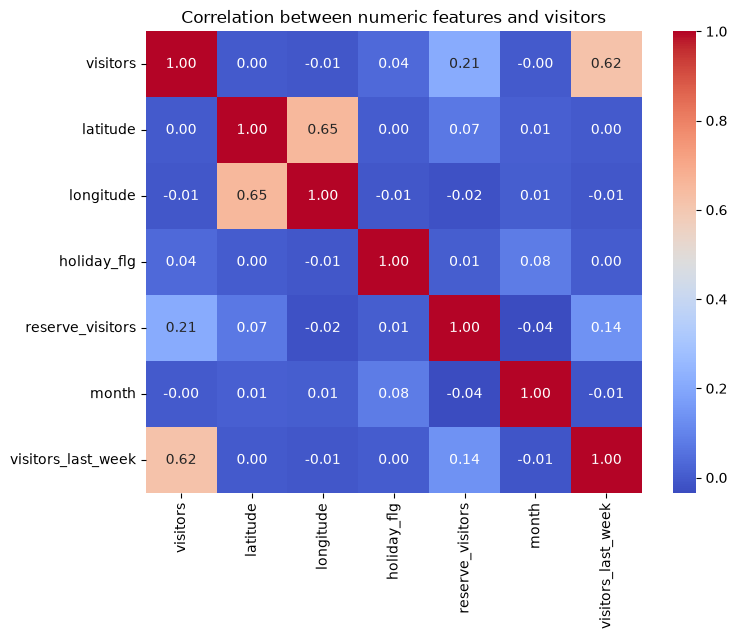

In [6]:
numeric_columns = df.select_dtypes("number")

plt.figure(figsize=(8, 6))
sns.heatmap(numeric_columns.corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlation between numeric features and visitors")
plt.show()


*What matters most*:Last week's visitors are strongest with correlation of 0.62 because they help us predict, and bookings are second with 0.21 because a booking means a person is planning to come. The rest which are latitude, longitude, month and holiday are all close to 0 which indicates that they have no straight line link with visitors.

*Decision*: I used the last week's visitors for the scatter plots because it's the strongest feature and i kept the weak features because tree models can still find patterns in them.


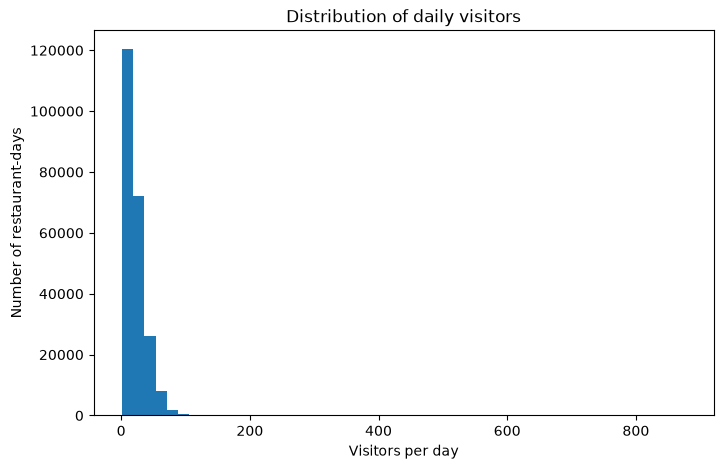

count    229263.000000
mean         21.453972
std          16.789681
min           1.000000
25%           9.000000
50%          18.000000
75%          30.000000
max         877.000000
Name: visitors, dtype: float64


In [7]:
plt.figure(figsize=(8, 5))
plt.hist(df["visitors"], bins=50)
plt.xlabel("Visitors per day")
plt.ylabel("Number of restaurant-days")
plt.title("Distribution of daily visitors")
plt.show()
print(df["visitors"].describe())


**What the histogram shows:** Most restaurant-days have between 9 and 30 visitors, around 18 in the middle. A few very busy days have very short bars far to the right, going up to 877, so the histogram is right-skewed.

*Decision*: I removed the 33 restaurant-days with more than 200 visitors because they would have a large MSE.



In [8]:
df = df[df["visitors"] <= 200]
print(df.shape)


(229230, 10)


## 4. Prepare data for training
We need a test set that we set to 20% of the data and the train set to be 80% because we will need the set that is not trained to see if our model can really test and predict different data from what we have trained to assure us that it has just not crammed.

We also have to change the words to numbers for example like monday into 0/1 columns since our model is maths and it cannot understand words.

We standardise to make sure that each number gets a fair chance on the same scale so that one feature doesn't look more important just because its numbers are bigger.

We use scaler on training data only so that the test data stays unseen and the test is fair.


In [9]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

X = df.drop(columns="visitors")
y = df["visitors"]

categorical_features = ["air_genre_name", "day_of_week", "prefecture"]
numeric_features = ["latitude", "longitude", "holiday_flg", "reserve_visitors", "month", "visitors_last_week"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

preprocessor = ColumnTransformer([
    ("categorical", OneHotEncoder(handle_unknown="ignore"), categorical_features),
    ("numeric", StandardScaler(), numeric_features),
])

X_train_prepared = preprocessor.fit_transform(X_train)
X_test_prepared = preprocessor.transform(X_test)

print("Train:", X_train_prepared.shape)
print("Test:", X_test_prepared.shape)


Train: (183384, 36)
Test: (45846, 36)


## 5. Model 1 – Linear regression with gradient descent (SGDRegressor)
SGD learns the line by nudging it step by step in the direction that makes the error become smaller. An epoch is the number of times SGD has gone through the training rows: one epoch means it has gone through the training rows once, and two epochs means it has gone through them twice. partial_fit trains one epoch at a time, while .fit() would train all the epochs in one go and only give the final answer, so we need the partial.fit() tnan .fit() to savw the train and test MSE after every epoch so that i can draw the loss curve.


In [10]:
from sklearn.linear_model import SGDRegressor
from sklearn.metrics import mean_squared_error

def train_sgd(learning_rate, alpha, epochs):
    model = SGDRegressor(learning_rate="constant", eta0=learning_rate, alpha=alpha, random_state=42)
    train_losses = []
    test_losses = []
    for epoch in range(epochs):
        model.partial_fit(X_train_prepared, y_train)
        train_losses.append(mean_squared_error(y_train, model.predict(X_train_prepared)))
        test_losses.append(mean_squared_error(y_test, model.predict(X_test_prepared)))
    return model, train_losses, test_losses


In [11]:
results = []

for learning_rate in [0.0001, 0.001, 0.01]:
    for alpha in [0.0001, 0.01, 0.1]:
        model, train_losses, test_losses = train_sgd(learning_rate, alpha, epochs=30)
        results.append({
            "learning_rate": learning_rate,
            "alpha": alpha,
            "train_mse": train_losses[-1],
            "test_mse": test_losses[-1],
        })

pd.DataFrame(results).sort_values("test_mse")


,learning_rate,alpha,train_mse,test_mse
0,0.0001,0.0001,152.066861,155.018513
1,0.0001,0.0100,152.875403,155.631277
2,0.0001,0.1000,155.156474,157.084011
8,0.0100,0.1000,163.839130,163.969034
5,0.0010,0.1000,162.431935,164.123479
7,0.0100,0.0100,164.558793,165.608158
6,0.0100,0.0001,165.330045,166.516491
4,0.0010,0.0100,169.700754,170.652160
3,0.0010,0.0001,170.359698,171.208044


**Tuning results:** The smaller learning rate of 0.0001 was good since it had a lower MSE (about 155) than the larger learning rates of 0.001 and 0.01 (about 164–171). I chose it because the larger learning rates were big steps that made the model keep jumping over the bottom. Alpha made only a little difference because there was no overfitting (train and test MSE were close). Best settings: learning rate 0.0001, alpha 0.0001.


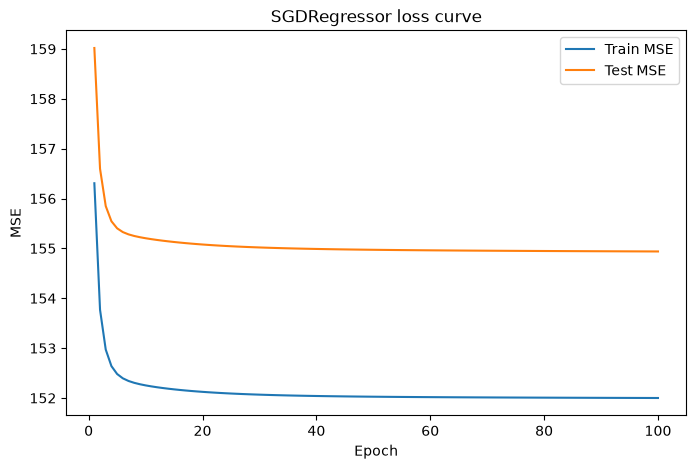

In [12]:
sgd_model, train_losses, test_losses = train_sgd(learning_rate=0.0001, alpha=0.0001, epochs=100)

plt.figure(figsize=(8, 5))
plt.plot(range(1, 101), train_losses, label="Train MSE")
plt.plot(range(1, 101), test_losses, label="Test MSE")
plt.xlabel("Epoch")
plt.ylabel("MSE")
plt.title("SGDRegressor loss curve")
plt.legend()
plt.show()


**What the loss curve shows:** Both losses drop quickly in the first ~10 epochs (test MSE from 159 to 155), then flatten – after about 30 epochs extra epochs barely help (155.02 at 30 epochs vs 154.94 at 100). The train and test curves stay close together, so the model is not overfitting. Its error is limited because a straight line cannot capture the non-linear patterns in restaurant visits.


## 6. Models 2–4 – Linear regression (closed form), Decision tree, Random forest


In [13]:
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor

linear_model = LinearRegression()
linear_model.fit(X_train_prepared, y_train)

tree_model = DecisionTreeRegressor(max_depth=10, random_state=42)
tree_model.fit(X_train_prepared, y_train)

forest_model = RandomForestRegressor(n_estimators=10, max_depth=10, min_samples_leaf=20, n_jobs=-1, random_state=42)
forest_model.fit(X_train_prepared, y_train)


,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",10
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",10
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",20
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"max

In [14]:
models = {
    "SGDRegressor": sgd_model,
    "LinearRegression": linear_model,
    "DecisionTree": tree_model,
    "RandomForest": forest_model,
}

comparison = []
for name, model in models.items():
    comparison.append({
        "model": name,
        "train_mse": mean_squared_error(y_train, model.predict(X_train_prepared)),
        "test_mse": mean_squared_error(y_test, model.predict(X_test_prepared)),
    })

comparison = pd.DataFrame(comparison).sort_values("test_mse")
comparison


,model,train_mse,test_mse
3,RandomForest,132.320926,135.915361
2,DecisionTree,132.109332,140.939379
1,LinearRegression,149.193379,150.408052
0,SGDRegressor,151.999814,154.938189


**Best model: Random Forest.** The best model was the random forest since it had the lowest test MSE (135.9).

- **SGDRegressor (154.9) and LinearRegression (150.4):** the straight-line models do worst because they miss a lot – restaurant visits depend on a mix of reasons (day, genre, place) that a straight line can't capture.
- **Decision tree (140.9):** did better because it asks yes and no questions, so it handles mixed reasons.
- **Random forest (135.9):** does best because it averages 10 trees, so the mistakes cancel out.


In [15]:
import joblib
from sklearn.pipeline import Pipeline

best_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", forest_model),
])

joblib.dump(best_model, "../API/best_model.pkl")
print("Saved best model to API/best_model.pkl")


Saved best model to API/best_model.pkl


In [16]:
df.to_csv("../API/training_data.csv", index=False)
print("Saved", df.shape, "to API/training_data.csv")


Saved (229230, 10) to API/training_data.csv


In [17]:
def predict_visitors(input_row):
    model = joblib.load("../API/best_model.pkl")
    return model.predict(input_row)[0]

one_row = X_test.iloc[[0]]
display(one_row)
print("Predicted visitors:", round(predict_visitors(one_row)))
print("Actual visitors:", y_test.iloc[0])


,air_genre_name,latitude,longitude,day_of_week,holiday_flg,reserve_visitors,prefecture,month,visitors_last_week
156124,Izakaya,34.688241,135.187254,Monday,0,0.0,Hyogo-ken,3,16.0


Predicted visitors: 18
Actual visitors: 22


## 7. Scatter plots – most correlated feature vs target
From the heatmap, `visitors_last_week` is the feature most correlated with `visitors` (0.62).


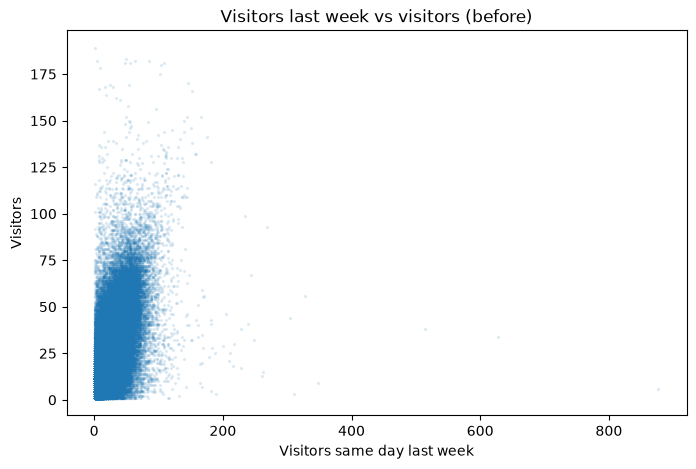

In [18]:
plt.figure(figsize=(8, 5))
plt.scatter(X_train["visitors_last_week"], y_train, s=2, alpha=0.1)
plt.xlabel("Visitors same day last week")
plt.ylabel("Visitors")
plt.title("Visitors last week vs visitors (before)")
plt.show()


**What it shows:** The upward trend means that the restaurants that were busy the previous week are busy the following week too. The dots are widely spread, so last week's visitors alone cannot predict visitors well.

**Decision:** The scatter plot confirms that the most important feature is the visitors of last week, but because of the spread I used all 9 features in the models.


c:\Users\hp\OneDrive\Desktop\linear_regression_model\summative\.venv\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


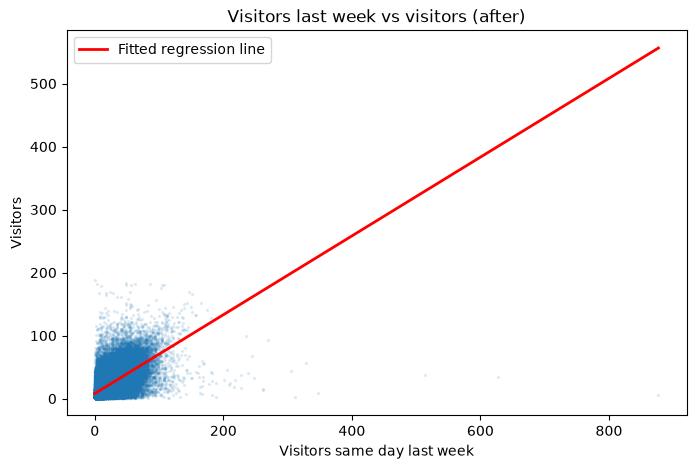

Slope: 0.625
Intercept: 8.05


In [19]:
line_model = LinearRegression()
line_model.fit(X_train[["visitors_last_week"]], y_train)

x_values = pd.DataFrame({"visitors_last_week": [0, X_train["visitors_last_week"].max()]})
y_values = line_model.predict(x_values)

plt.figure(figsize=(8, 5))
plt.scatter(X_train["visitors_last_week"], y_train, s=2, alpha=0.1)
plt.plot(x_values, y_values, color="red", linewidth=2, label="Fitted regression line")
plt.xlabel("Visitors same day last week")
plt.ylabel("Visitors")
plt.title("Visitors last week vs visitors (after)")
plt.legend()
plt.show()

print("Slope:", round(line_model.coef_[0], 3))
print("Intercept:", round(line_model.intercept_, 2))


**What it shows:** The fitted line is `visitors = 0.625 × visitors_last_week + 8.05`. For every extra visitor last week, we expect about 0.6 more visitors this week, plus a base of about 8.

**Decision:** The slope is below 1, which means busy days tend to be followed by slightly quieter ones (and quiet days by slightly busier ones). Many points are far from the line, which is why non-linear models like the random forest perform better.


## 8. Sample file for testing /retrain


In [20]:
df.sample(200, random_state=7).to_csv("data/new_data_sample.csv", index=False)
print("Saved 200 rows to data/new_data_sample.csv")


Saved 200 rows to data/new_data_sample.csv
